In [10]:
#Libraries
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [11]:
#Set time to extract historical data
#years = 15
endDate = dt.datetime(2023, 10, 31)
startDate = dt.datetime(2023, 10, 1)



In [12]:
#create a list for tickers
tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']

In [13]:
#download adjusted close prices
adj_close_df = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate)
    adj_close_df[ticker] = data['Adj Close']
print(adj_close_df)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
                   SPY        BND         GLD         QQQ         VTI
Date                                                                 
2023-10-02  427.309998  68.905281  169.649994  361.260010  212.130005
2023-10-03  421.589996  68.346939  169.160004  354.920013  209.050003
2023-10-04  424.660004  68.795609  169.139999  359.750000  210.559998
2023-10-05  424.500000  68.845459  168.830002  358.690002  210.449997
2023-10-06  429.540009  68.576256  169.699997  364.700012  212.960007
2023-10-09  432.290009  69.274185  172.820007  366.559998  214.300003
2023-10-10  434.540009  69.204391  172.529999  368.589996  215.630005
2023-10-11  436.320007  6

In [14]:
#calculate daily log returns and drop na
log_returns = np.log(adj_close_df/adj_close_df.shift(1))
log_returns = log_returns.dropna()
print(log_returns)

                 SPY       BND       GLD       QQQ       VTI
Date                                                        
2023-10-03 -0.013476 -0.008136 -0.002892 -0.017705 -0.014626
2023-10-04  0.007256  0.006543 -0.000118  0.013517  0.007197
2023-10-05 -0.000377  0.000724 -0.001834 -0.002951 -0.000523
2023-10-06  0.011803 -0.003918  0.005140  0.016617  0.011856
2023-10-09  0.006382  0.010126  0.018218  0.005087  0.006273
2023-10-10  0.005191 -0.001008 -0.001680  0.005523  0.006187
2023-10-11  0.004088  0.004600  0.007277  0.007110  0.003934
2023-10-12 -0.006115 -0.008642 -0.003054 -0.003481 -0.008070
2023-10-13 -0.004993  0.004618  0.031642 -0.012650 -0.005651
2023-10-16  0.010466 -0.005197 -0.004877  0.011243  0.011547
2023-10-17 -0.000046 -0.006535  0.001853 -0.003281  0.001295
2023-10-18 -0.013415 -0.004380  0.014367 -0.013205 -0.014905
2023-10-19 -0.008825 -0.004399  0.012199 -0.009401 -0.009477
2023-10-20 -0.012364  0.003668  0.002727 -0.015030 -0.012442
2023-10-23 -0.001735  0.

In [15]:
#Create equally weighted portfolio
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
print(weights)

[0.2 0.2 0.2 0.2 0.2]


In [16]:
#calculate historical porfolio return
historical_returns = (log_returns*weights).sum(axis=1)
print(historical_returns)

Date
2023-10-03   -0.011367
2023-10-04    0.006879
2023-10-05   -0.000992
2023-10-06    0.008300
2023-10-09    0.009217
2023-10-10    0.002843
2023-10-11    0.005402
2023-10-12   -0.005873
2023-10-13    0.002593
2023-10-16    0.004637
2023-10-17   -0.001343
2023-10-18   -0.006308
2023-10-19   -0.003981
2023-10-20   -0.006688
2023-10-23   -0.000208
2023-10-24    0.005591
2023-10-25   -0.011517
2023-10-26   -0.006686
2023-10-27    0.001282
2023-10-30    0.005282
dtype: float64


In [23]:
#find x day historical retuns i.e. rolling averages
days = 1

range_returns = historical_returns.rolling(window = days).sum()
range_returns = range_returns.dropna()
print(range_returns)

Date
2023-10-03   -0.011367
2023-10-04    0.006879
2023-10-05   -0.000992
2023-10-06    0.008300
2023-10-09    0.009217
2023-10-10    0.002843
2023-10-11    0.005402
2023-10-12   -0.005873
2023-10-13    0.002593
2023-10-16    0.004637
2023-10-17   -0.001343
2023-10-18   -0.006308
2023-10-19   -0.003981
2023-10-20   -0.006688
2023-10-23   -0.000208
2023-10-24    0.005591
2023-10-25   -0.011517
2023-10-26   -0.006686
2023-10-27    0.001282
2023-10-30    0.005282
dtype: float64


In [29]:
#specify confidence interval and calculate VaR
confidence_interval = 0.99

VaR = -np.percentile(range_returns, 100 - (confidence_interval * 100))*portfolio_value
print(VaR)

11488.363175047452


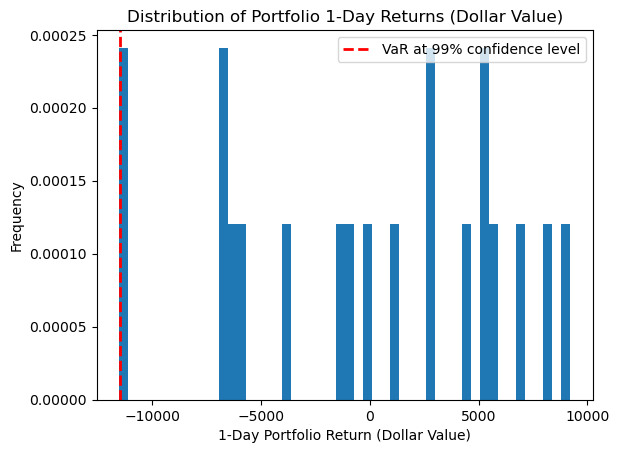

In [25]:
return_window = days
range_returns = historical_returns.rolling(window=return_window).sum()
range_returns = range_returns.dropna()

range_returns_dollar = range_returns * portfolio_value

plt.hist(range_returns_dollar.dropna(), bins=50, density=True)
plt.xlabel(f'{return_window}-Day Portfolio Return (Dollar Value)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio {return_window}-Day Returns (Dollar Value)')
plt.axvline(-VaR, color='r', linestyle='dashed', linewidth=2, label=f'VaR at {confidence_interval:.0%} confidence level')
plt.legend()
plt.show()